# Example of the aitlas toolbox in the context of object detection in remote sensing images

## Import the required packages

In [ ]:
import sys
sys.path.insert(0, "..")  # makes the datasets package of this repository importable
from datasets import CARPKDataset
from aitlas.transforms import Resize
from aitlas.utils import image_loader
from aitlas.models import FasterRCNN

## Visualize images and objects witn bounding boxes

Total number of patches: 1448


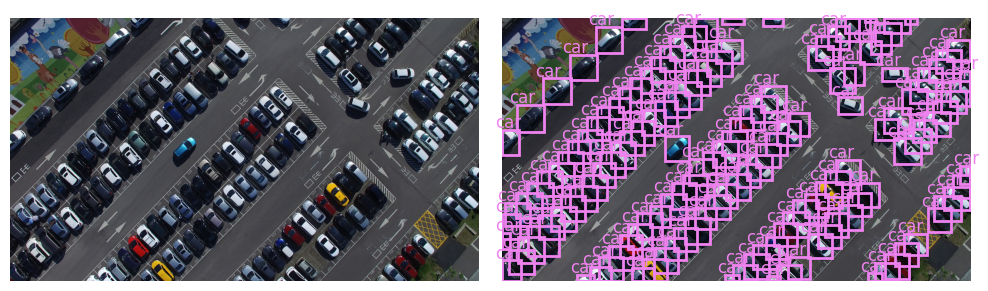

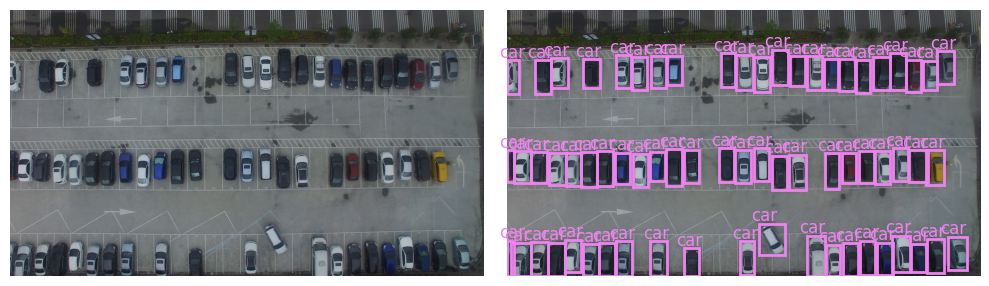

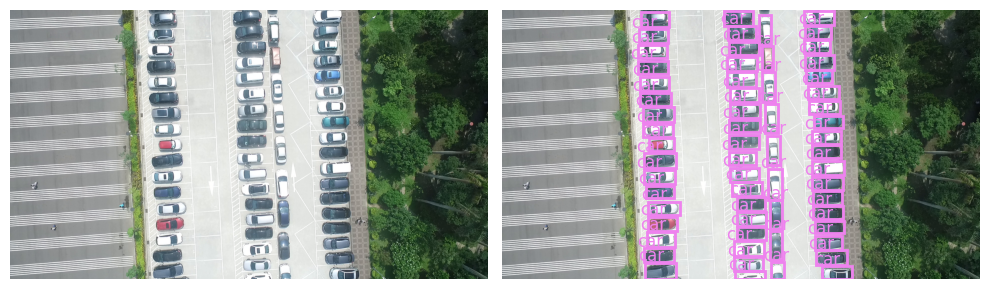

In [ ]:
dataset_config = {
    "data_dir": "./data/CARPK/Images/",
    "annotation_dir": "./data/CARPK/Annotations/",
}
dataset = CARPKDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")
dataset.show_image(5);
dataset.show_image(10);
dataset.show_image(100);

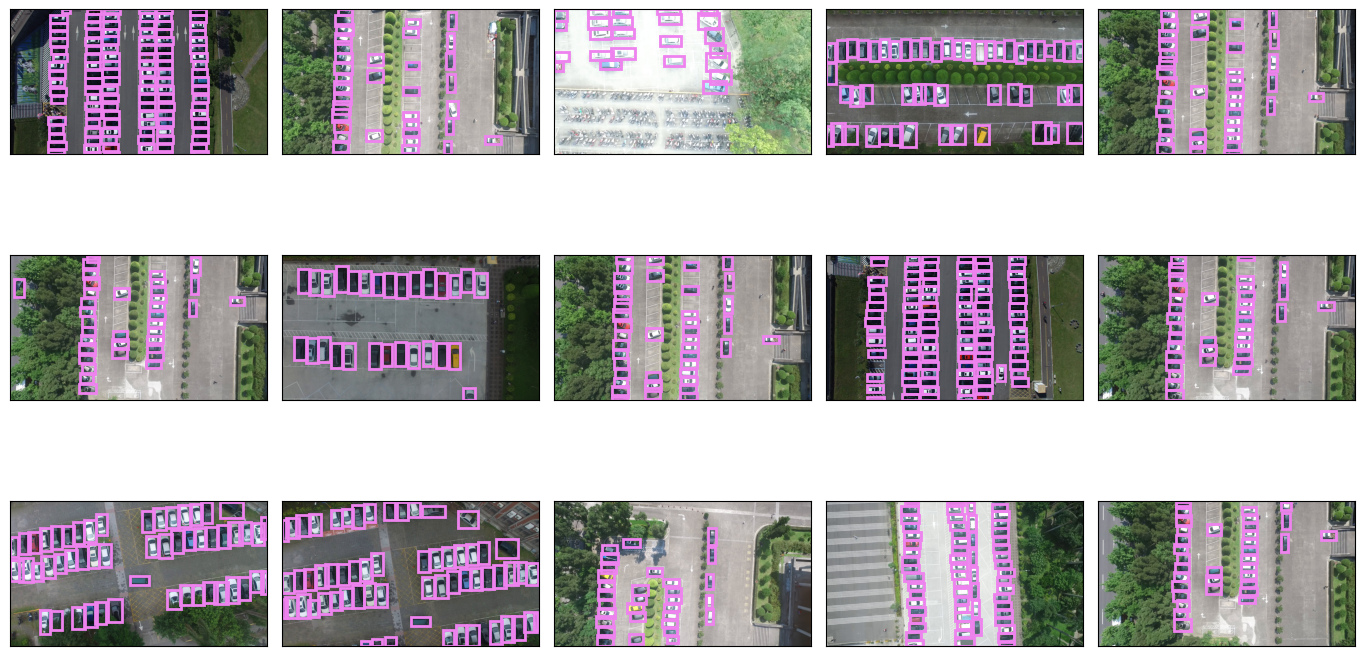

In [31]:
dataset.show_batch(15);

In [8]:
dataset.data_distribution_table()

,Label,Count
0,car,77706


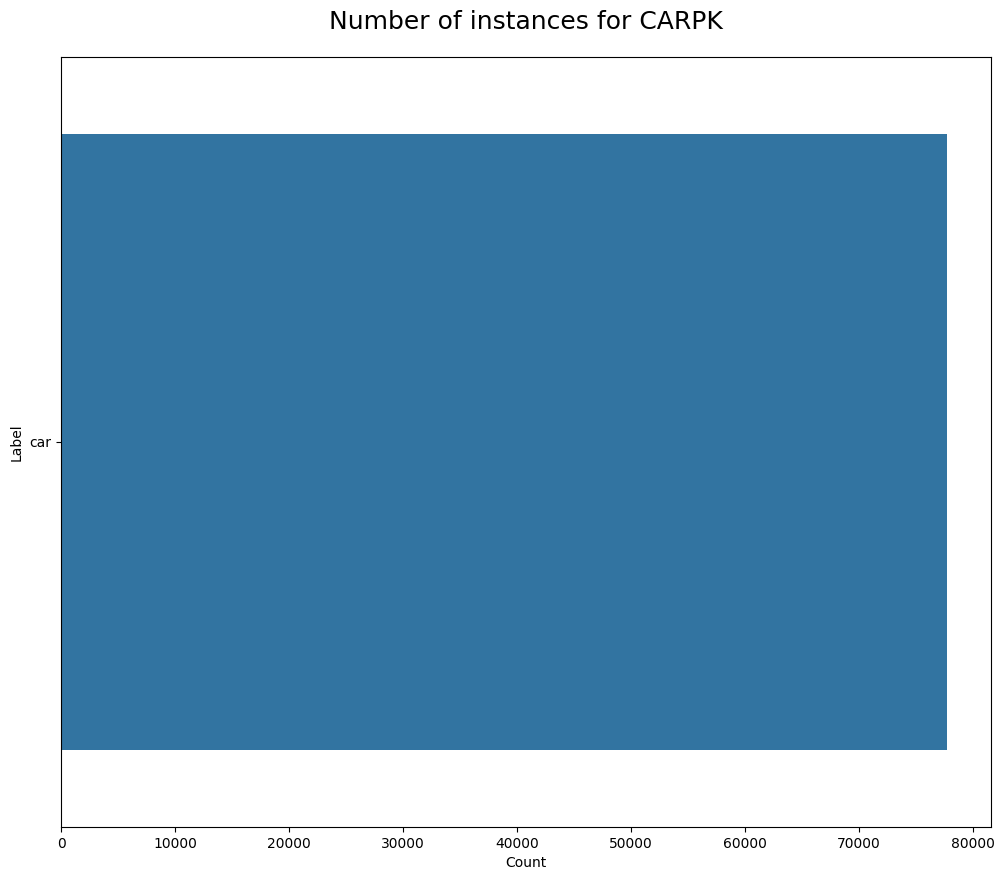

In [33]:
dataset.data_distribution_barchart();

## Load train data

In [ ]:
train_dataset_config = {
    "batch_size": 8,
    "shuffle": True,
    "num_workers": 4,
    "data_dir": "./data/CARPK/Images/",
    "annotation_dir": "./data/CARPK/Annotations/",
    "csv_file":"./data/CARPK/ImageSets/train.txt",
    "joint_transforms": ["aitlas.transforms.ResizeToTensorV2"]
}
train_dataset = CARPKDataset(train_dataset_config)

print(f"Total number of train images: {len(train_dataset)}")

Total number of train images: 989


## Create the model

In [ ]:
epochs = 10
model_directory = "./data/CARPK/"
model_config = {
    "num_classes": 2,
    "learning_rate": 0.0001,
    "pretrained": True,
    "metrics": ["map"]
}

model = FasterRCNN(model_config)
model.prepare()

## Start the training

In [12]:
model.train_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1'
);

2025-04-28 07:24:29,956 INFO Starting training.
training: 100%|██████████| 124/124 [00:42<00:00,  2.89it/s]
2025-04-28 07:25:13,226 INFO epoch: 1, time: 43, loss:  0.33161
testing on train set: 100%|██████████| 124/124 [00:23<00:00,  5.31it/s]
2025-04-28 07:26:25,347 INFO map:0.8004003167152405, map_50:0.9897754192352295, map_75:0.9875259399414062, map_small:0.7794407606124878, map_medium:0.822966456413269, map_large:-1.0, mar_1:0.02018025331199169, mar_10:0.19995032250881195, mar_100:0.8442777991294861, mar_small:0.8292086720466614, mar_medium:0.8614749312400818, mar_large:-1.0, map_per_class:0.8004003167152405, mar_100_per_class:0.8442777991294861, classes:1.0
training: 100%|██████████| 124/124 [00:43<00:00,  2.87it/s]
2025-04-28 07:27:08,538 INFO epoch: 2, time: 43, loss:  0.20080
testing on train set: 100%|██████████| 124/124 [00:23<00:00,  5.24it/s]
2025-04-28 07:28:18,397 INFO map:0.8224199414253235, map_50:0.9897714257240295, map_75:0.9888403415679932, map_small:0.80366903543472

## Evaluate the model

In [ ]:
test_dataset_config = {
    "batch_size": 8,
    "shuffle": False,
    "data_dir": "./data/CARPK/Images/",
    "annotation_dir": "./data/CARPK/Annotations/",
    "csv_file":"./data/CARPK/ImageSets/test.txt",
    "joint_transforms": ["aitlas.transforms.ResizeToTensorV2"]
}

test_dataset = CARPKDataset(test_dataset_config)
print(f"Total number of test images: {len(test_dataset)}")

model = FasterRCNN(model_config)
model.prepare()
model.running_metrics.reset()
model_path = "./data/CARPK/checkpoint.pth.tar"
model.evaluate(dataset=test_dataset, model_path=model_path)
model.running_metrics.get_scores(model.metrics)

Total number of test images: 459


2025-04-28 07:51:42,477 INFO Loading checkpoint /home/dragik/data/FAIR_EO/CARPK/checkpoint.pth.tar
2025-04-28 07:51:42,860 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/CARPK/checkpoint.pth.tar at epoch 11
testing on test set: 100%|██████████| 58/58 [00:18<00:00,  3.12it/s]


[{'map': 0.4567520022392273,
  'map_50': 0.7898894548416138,
  'map_75': 0.4893796145915985,
  'map_small': 0.45391646027565,
  'map_medium': 0.5345388054847717,
  'map_large': -1.0,
  'mar_1': 0.00647157896310091,
  'mar_10': 0.0626673698425293,
  'mar_100': 0.5121957659721375,
  'mar_small': 0.49858981370925903,
  'mar_medium': 0.6035563349723816,
  'mar_large': -1.0,
  'map_per_class': 0.4567520022392273,
  'mar_100_per_class': 0.5121957659721375,
  'classes': 1.0}]

## Predictions

2025-04-28 07:53:50,484 INFO Loading checkpoint /home/dragik/data/FAIR_EO/CARPK/checkpoint.pth.tar
2025-04-28 07:53:50,871 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/CARPK/checkpoint.pth.tar at epoch 11


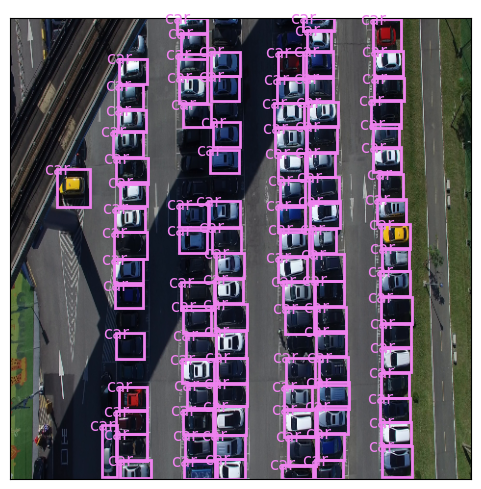

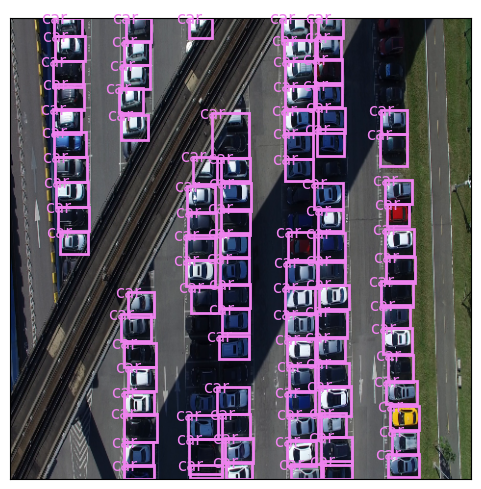

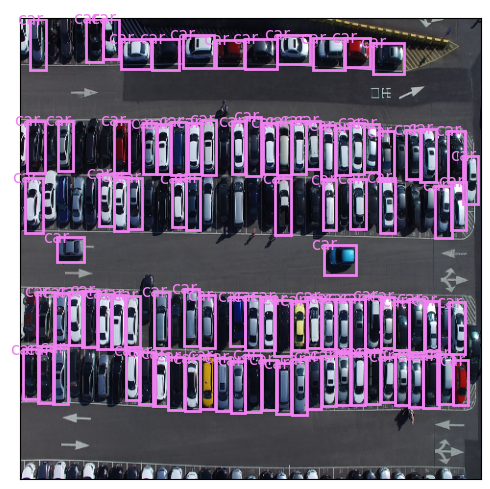

In [ ]:
model_config = {
    "num_classes": 2,
    "learning_rate": 0.0001,
    "pretrained": True,
    "metrics": ["map"]
}
model = FasterRCNN(model_config)
model.prepare()

model_path = "./data/CARPK/checkpoint.pth.tar"
labels = ["no-data","car"]
transform = Resize()
model.load_model(model_path)
csv_file = "./data/CARPK/ImageSets/test.txt"

test_list = []
with open(csv_file, mode ='r')as file:
    for lines in file:
        lines = lines[:-1] #removes the '/n'
        test_list.append(lines)

image = image_loader('./data/CARPK/Images/' + test_list[0] + '.png')
fig = model.detect_objects(image, labels, transform)

image = image_loader('./data/CARPK/Images/' + test_list[1] + '.png')
fig = model.detect_objects(image, labels, transform)

image = image_loader('./data/CARPK/Images/' + test_list[10] + '.png')
fig = model.detect_objects(image, labels, transform)